In [3]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [4]:
df_filtered = df[pd.notna(df['salary_year_avg'])].copy()

def projected_salary(salary):
    return salary * 1.03

df_filtered['salary_year_inflated']=df_filtered['salary_year_avg'].apply(lambda salary:salary*1.03)
df_filtered[['salary_year_avg', 'salary_year_inflated']]

,salary_year_avg,salary_year_inflated
28,109500.0,112785.00
77,140000.0,144200.00
92,120000.0,123600.00
100,228222.0,235068.66
109,89000.0,91670.00
...,...,...
785624,139216.0,143392.48
785641,150000.0,154500.00
785648,221875.0,228531.25
785682,157500.0,162225.00


In [5]:
import ast
def clean_list(skill_list):
    if pd.notna(skill_list):
        return ast.literal_eval(skill_list)

#df['job_skills'] = df['job_skills'].apply(clean_list)
df['job_skills'] = df['job_skills'].apply(lambda skill_list : ast.literal_eval(skill_list) if pd.notna(skill_list) else skill_list)

In [6]:
df['job_skills'][6]

['sql', 'python', 'java', 'sql server', 'gcp', 'bigquery', 'hadoop']

In [9]:
def projected_salary(row):
    if "Senior" in row['job_title_short']:
        return 1.05 * row['salary_year_avg']
    else:
        return 1.05 * row['salary_year_avg']

df_filtered['salary_year_inflated'] = df_filtered.apply(projected_salary, axis=1)

df_filtered[['job_title_short','salary_year_avg','salary_year_inflated']]

,job_title_short,salary_year_avg,salary_year_inflated
28,Data Scientist,109500.0,114975.00
77,Data Engineer,140000.0,147000.00
92,Data Engineer,120000.0,126000.00
100,Data Scientist,228222.0,239633.10
109,Data Analyst,89000.0,93450.00
...,...,...,...
785624,Data Engineer,139216.0,146176.80
785641,Data Engineer,150000.0,157500.00
785648,Data Scientist,221875.0,232968.75
785682,Data Scientist,157500.0,165375.00


In [10]:
df[['job_title_short','job_skills']].head()

,job_title_short,job_skills
0,Senior Data Engineer,NaN
1,Data Analyst,"[r, python, sql, nosql, power bi, tableau]"
2,Data Engineer,"[python, sql, c#, azure, airflow, dax, docker,..."
3,Data Engineer,"[python, c++, java, matlab, aws, tensorflow, k..."
4,Data Engineer,"[bash, python, oracle, aws, ansible, puppet, j..."


In [17]:
df_exploded = df.explode('job_skills')
skills_count= df_exploded.groupby(['job_title_short','job_skills']).size()

In [23]:
df_skills_count=skills_count.reset_index(name = 'skill_count')
df_skills_count = df_skills_count.sort_values(by='skill_count', ascending=False)
df_skills_count

,job_title_short,job_skills,skill_count
1066,Data Scientist,python,113711
865,Data Engineer,sql,113130
830,Data Engineer,python,108022
625,Data Analyst,sql,92428
1101,Data Scientist,sql,78982
...,...,...,...
462,Data Analyst,chainer,1
432,Cloud Engineer,wrike,1
410,Cloud Engineer,theano,1
24,Business Analyst,chainer,1


In [26]:
job_title="Data Analyst"
top_skills=10

df_skill_final = df_skills_count[df_skills_count['job_title_short'] == job_title].head(top_skills)
df_skill_final

,job_title_short,job_skills,skill_count
625,Data Analyst,sql,92428
494,Data Analyst,excel,66860
590,Data Analyst,python,57190
638,Data Analyst,tableau,46455
583,Data Analyst,power bi,39380
594,Data Analyst,r,29996
606,Data Analyst,sas,27998
585,Data Analyst,powerpoint,13822
664,Data Analyst,word,13562
605,Data Analyst,sap,11280


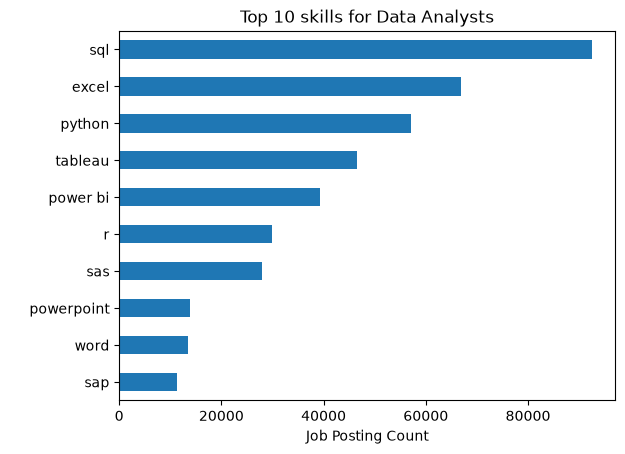

In [31]:
df_skill_final.plot(kind='barh', x='job_skills', y='skill_count')
plt.gca().invert_yaxis()
plt.title(f'Top {top_skills} skills for {job_title}s')
plt.xlabel('Job Posting Count')
plt.ylabel(' ')
plt.legend().set_visible(False)
plt.show()